# 単語埋め込み（分散表現）と文脈付き埋め込みの比較

書籍 第2章「分類・回帰問題の解き方」（分散表現・事前学習済み言語モデル）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、静的単語埋め込みから文脈付き埋め込み（Contextual Embeddings）への発展を段階的に体験します。

1. **静的単語埋め込み（PPMI + SVD による分散表現）**：共起行列から PPMI 行列と特異値分解（SVD）で密な単語ベクトルを構築し、コサイン類似度による近傍語検索と 2 次元可視化（PCA）を行います。
2. **静的埋め込みの限界（多義語が 1 ベクトルに潰れる問題）**：「アップル（果物 vs IT 企業）」「バンク（金融機関 vs 川岸・土手）」のような多義語が、複数の語義の中間に位置してしまう現象を定量的に確認します。
3. **文脈付き埋め込み（Contextual Embeddings）による多義語の分離**：
   - CPU のみで原理を体感できる **簡易 Self-Attention 型文脈ベクトル** を実装し、文脈に応じて多義語が異なるベクトル空間上のクラスタに分離することを可視化します。
   - 最後に、Google Colab 等で実行できる **日本語 BERT（`tohoku-nlp/bert-base-japanese-v3`）による実際の文脈付き埋め込み抽出コード** を掲載します。

In [1]:
!pip install -q matplotlib-fontja

In [2]:
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib_fontja  # noqa: F401
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity

plt.rcParams["axes.unicode_minus"] = False

---

## 1. 静的単語埋め込み（PPMI + SVD による分散表現）

**分布仮説（Distributional Hypothesis）** によれば、「似た文脈に出現する単語は似た意味を持つ」と考えられます。
ここでは外部ライブラリに頼らず、複数ドメインの日本語コーパス（分かち書き済み）から以下の手順で**静的単語埋め込み**を構築します。

1. ウィンドウ幅 $w = 2$ で単語同士の**共起行列** $C$ を数える
2. 頻出語の偏りを補正するため **PPMI（Positive Pointwise Mutual Information）** を計算する
   $$\mathrm{PPMI}(i, j) = \max\left(0, \log_2 \frac{P(i, j)}{P(i) P(j)}\right)$$
3. **特異値分解（Truncated SVD）** で低次元（$d = 8$）に圧縮し、各単語の密な分散表現ベクトルを得る

コーパスには意図的に以下の**多義語**を含めています。
- **アップル**：果物・スイーツ文脈 と IT 企業・製品文脈
- **バンク**：金融・銀行文脈 と 川岸・土手（リバーバンク）文脈
- **走る**：スポーツ・陸上文脈 と 鉄道・電車文脈

In [3]:
# 6つのドメイン（果物・IT・金融・河川・スポーツ・鉄道）からなる分かち書き済み日本語コーパス
corpus_sentences = [
    # --- 果物・料理ドメイン ---
    "りんご は 甘い 果物 で ジュース や パイ に 使う",
    "バナナ と オレンジ と りんご を デザート に 食べる",
    "ぶどう と いちご は 甘い 果実 で 農家 が 収穫 する",
    "新鮮 な りんご を 絞っ て 甘い ジュース を 作る",
    "農家 が 収穫 し た オレンジ と ぶどう は とても 甘い",
    "いちご と バナナ の デザート は 子ども に 人気 の 果物 だ",
    "秋 に 収穫 し た りんご で 温かい パイ を 焼く",
    "朝 の 食卓 で 甘い ジュース と 新鮮 な 果物 を 食べる",
    "ぶどう と りんご の 甘い 香り が デザート に 広がる",
    "果物 農家 は いちご や オレンジ を 丁寧 に 収穫 する",
    "新鮮 な バナナ と りんご を 混ぜ た ジュース を 食べる",
    "温かい パイ に 甘い 果実 と りんご を たっぷり 使う",
    # 多義語「アップル」（果物文脈）
    "アップル は 甘い 果物 で パイ や ジュース に 使う",
    "新鮮 な アップル を 絞っ て 甘い ジュース を 作る",
    "農家 が 収穫 し た アップル と ぶどう を デザート に 食べる",
    "温かい アップル パイ は 甘い 果実 の 香り が する",
    "果物 売り場 で 甘い アップル と オレンジ を 買う",
    "いちご と アップル を 使っ た デザート を 食べる",

    # --- IT・テクノロジードメイン ---
    "パソコン と スマホ の 新しい ソフトウェア を エンジニア が 開発 する",
    "IT 企業 が 新しい スマホ 端末 と OS の 製品 を 発表 する",
    "アプリ の 開発 に は 優秀 な エンジニア と ソフトウェア が 必要 だ",
    "新しい パソコン 製品 の 売上 が 伸び て 企業 の 株価 が 上がる",
    "スマホ 向け の 便利 な アプリ と OS を 企業 が 発表 する",
    "エンジニア は 端末 向け の ソフトウェア と アプリ を 開発 する",
    "人気 の 端末 製品 の 売上 で IT 企業 の 株価 が 急上昇 する",
    "パソコン と スマホ の OS を 最新 ソフトウェア に 更新 する",
    "IT 企業 の 新 製品 発表 で エンジニア が アプリ を 紹介 する",
    "端末 と ソフトウェア の 売上 が 好調 で 企業 の 株価 は 堅調 だ",
    "新しい OS と アプリ を 搭載 し た スマホ 端末 を 開発 する",
    "企業 の エンジニア が パソコン 向け ソフトウェア 製品 を 発表 する",
    # 多義語「アップル」（IT企業文脈）
    "アップル が 新しい スマホ 端末 と OS 製品 を 発表 する",
    "アップル の パソコン と スマホ の 売上 が 伸び て 株価 が 上がる",
    "アップル の エンジニア が 新しい ソフトウェア と アプリ を 開発 する",
    "IT 企業 の アップル が 最新 端末 向け OS を 発表 する",
    "アップル 製品 の ソフトウェア と アプリ は エンジニア に 人気 だ",
    "アップル の 新 製品 発表 で 株価 と 売上 の 注目 が 集まる",

    # --- 金融・経済ドメイン ---
    "銀行 の 口座 に 預金 を 入れる と 金利 が つく",
    "企業 は 銀行 から 融資 を 受け て 資金 を 調達 する",
    "支店 の 窓口 で 口座 開設 と 預金 と 融資 の 相談 を する",
    "証券 会社 と 銀行 が 投資 と 為替 の 決算 報告 を 出す",
    "金利 の 上昇 で 預金 の 利子 と 融資 の 資金 コスト が 変わる",
    "投資 家 は 証券 と 為替 の 動き を 見 て 資金 を 運用 する",
    "銀行 の 支店 は 融資 と 預金 の 決算 業務 を 担当 する",
    "新しい 口座 を 作り 証券 投資 と 為替 取引 を 始める",
    "資金 を 預金 し て 銀行 の 金利 と 決算 を 確認 する",
    "融資 の 金利 条件 を 銀行 の 支店 で 確認 する",
    # 多義語「バンク」（金融文脈）
    "バンク の 口座 に 預金 を 預け て 金利 を 確認 する",
    "企業 が バンク から 融資 を 受け て 資金 を 確保 する",
    "バンク の 支店 で 投資 と 証券 と 為替 の 相談 を する",
    "バンク の 決算 では 預金 と 融資 の 残高 が 増え た",
    "新しい バンク 口座 で 資金 の 運用 と 投資 を 始める",

    # --- 河川・自然ドメイン ---
    "川 の 堤防 と 土手 に 桜 が 咲き 景色 が 美しい",
    "河川 の 水面 が 光り 橋 の 近く を 散歩 する",
    "緑 豊か な 土手 と 堤防 沿い で 川 の 流れ を 眺める",
    "春 に なる と 河川 の 堤防 の 桜 を 見 ながら 散歩 する",
    "橋 の 上 から 穏やか な 川 の 水面 と 流れ を 見る",
    "川 沿い の 緑 の 土手 は 朝 の 散歩 に 最適 な 景色 だ",
    "河川 の 水面 に 桜 と 緑 の 景色 が 映り 流れ が 穏やか だ",
    "橋 を 渡っ て 堤防 と 土手 の 桜 並木 を 散歩 する",
    "川 の 流れ を 聞き ながら 緑 の 河川 敷 を 歩く",
    "美しい 水面 と 橋 の 景色 が 土手 から 一望 できる",
    # 多義語「バンク」（川岸・土手文脈）
    "川 の バンク に 桜 が 咲き 水面 の 景色 が 美しい",
    "河川 の バンク 沿い の 土手 と 堤防 を 散歩 する",
    "緑 豊か な バンク から 川 の 流れ と 橋 を 眺める",
    "橋 の 近く の バンク で 水面 と 桜 を 見 ながら 散歩 する",
    "朝 の バンク は 緑 と 川 の 流れ が 心地よい 景色 だ",

    # --- スポーツ・運動ドメイン ---
    "マラソン の 選手 は 毎日 練習 し て ゴール の タイム を 縮める",
    "陸上 競技 の 選手 が トレーニング で フォーム を 鍛える",
    "大会 の ゴール を 目指し て マラソン 選手 が 練習 を 続ける",
    "陸上 競技 で 自己 ベスト の タイム を 出す ため トレーニング する",
    "選手 は マラソン の 練習 で タイム を 計測 し ゴール する",
    # 多義語「走る」（スポーツ文脈）
    "マラソン の 選手 が 競技 場 を 全力 で 走る",
    "陸上 の 選手 は 毎日 トレーニング で タイム を 測り 走る",
    "ゴール を 目指し て マラソン 選手 が 練習 で 走る",
    "陸上 競技 の 選手 が 自己 ベスト の タイム で 走る",

    # --- 交通・鉄道ドメイン ---
    "電車 と 新幹線 が 路線 の 駅 に 定刻 で 停車 する",
    "新しい 車両 が 路線 の ダイヤ 通り に 運行 する",
    "駅 の ホーム に 電車 が 停車 し 新幹線 の ダイヤ を 確認 する",
    "新幹線 の 車両 は 主要 駅 の 路線 を 高速 で 運行 する",
    "朝 の ダイヤ は 電車 の 運行 本数 が 多く 駅 に 停車 する",
    # 多義語「走る」（鉄道文脈）
    "最新 の 新幹線 車両 が 路線 を 高速 で 走る",
    "朝 の ダイヤ 通り に 電車 が 駅 の 間 を 走る",
    "この 路線 は 電車 と 新幹線 の 車両 が 運行 し 走る",
    "各駅 停車 の 電車 が ダイヤ に 従っ て 路線 を 走る",
]

tokenized_corpus = [s.split() for s in corpus_sentences]
print(f"文数: {len(tokenized_corpus)}, 総トークン数: {sum(len(s) for s in tokenized_corpus)}")

文数: 84, 総トークン数: 997


In [4]:
# 語彙の構築（機能語を除いた内容語を中心に、出現回数 >= 2 の語を採用）
stopwords = {"は", "が", "を", "に", "で", "と", "の", "も", "や", "へ", "から", "まで", "な", "だ", "た", "て", "し", "する", "いる", "ある", "この"}
word_counts = Counter(w for sent in tokenized_corpus for w in sent if w not in stopwords)
vocab = [w for w, c in word_counts.most_common() if c >= 2]
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)
print(f"語彙数: {V}")

# 共起行列の構築（ウィンドウ幅 = 2、距離による重み付け 1/d）
window_size = 2
cooc = np.zeros((V, V), dtype=np.float64)
for sent in tokenized_corpus:
    filtered = [w for w in sent if w in word2idx]
    for i, target in enumerate(filtered):
        ti = word2idx[target]
        for offset in range(-window_size, window_size + 1):
            if offset == 0:
                continue
            j = i + offset
            if 0 <= j < len(filtered):
                ci = word2idx[filtered[j]]
                cooc[ti, ci] += 1.0 / abs(offset)

# PPMI 行列の計算
total = cooc.sum()
row_sum = cooc.sum(axis=1, keepdims=True)
col_sum = cooc.sum(axis=0, keepdims=True)
with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.log2((cooc * total) / (row_sum * col_sum))
ppmi = np.maximum(np.nan_to_num(pmi, nan=0.0, posinf=0.0, neginf=0.0), 0.0)

# Truncated SVD による 8 次元静的埋め込み
embed_dim = 8
svd = TruncatedSVD(n_components=embed_dim, random_state=42)
raw_embeddings = svd.fit_transform(ppmi)
# コサイン類似度計算のため L2 正規化
norms = np.linalg.norm(raw_embeddings, axis=1, keepdims=True)
static_embeddings = raw_embeddings / np.maximum(norms, 1e-12)

print(f"埋め込み行列の形状: {static_embeddings.shape}, 寄与率合計: {svd.explained_variance_ratio_.sum():.3f}")

def nearest_neighbors(word, top_k=6):
    idx = word2idx[word]
    sims = static_embeddings @ static_embeddings[idx]
    order = np.argsort(-sims)
    return [(idx2word[i], round(float(sims[i]), 3)) for i in order if i != idx][:top_k]

for query in ["りんご", "スマホ", "銀行", "川", "アップル", "バンク"]:
    nns = nearest_neighbors(query, top_k=6)
    print(f"「{query}」の近傍語: {nns}")

語彙数: 104
埋め込み行列の形状: (104, 8), 寄与率合計: 0.443
「りんご」の近傍語: [('香り', 1.0), ('農家', 0.999), ('果実', 0.999), ('収穫', 0.999), ('甘い', 0.999), ('オレンジ', 0.998)]
「スマホ」の近傍語: [('OS', 0.999), ('パソコン', 0.993), ('ソフトウェア', 0.987), ('端末', 0.986), ('エンジニア', 0.98), ('向け', 0.978)]
「銀行」の近傍語: [('支店', 0.992), ('受け', 0.992), ('融資', 0.99), ('決算', 0.987), ('口座', 0.982), ('預金', 0.979)]
「川」の近傍語: [('橋', 0.999), ('流れ', 0.999), ('美しい', 0.997), ('沿い', 0.996), ('近く', 0.994), ('豊か', 0.994)]
「アップル」の近傍語: [('デザート', 0.913), ('果物', 0.911), ('温かい', 0.904), ('バナナ', 0.899), ('絞っ', 0.897), ('新鮮', 0.896)]
「バンク」の近傍語: [('豊か', 0.863), ('近く', 0.856), ('沿い', 0.837), ('川', 0.832), ('緑', 0.827), ('河川', 0.822)]


上の出力を確認すると、単義語（「りんご」「スマホ」「銀行」「川」）はそれぞれ同じドメインの語と高い類似度を示しています。
一方で、**「アップル」** の近傍語には果物系の単語が並び、**「バンク」** の近傍語にも河川系の単語が並んでいることが分かります。

続いて、各単語ベクトルを PCA で 2 次元に射影して可視化してみましょう。

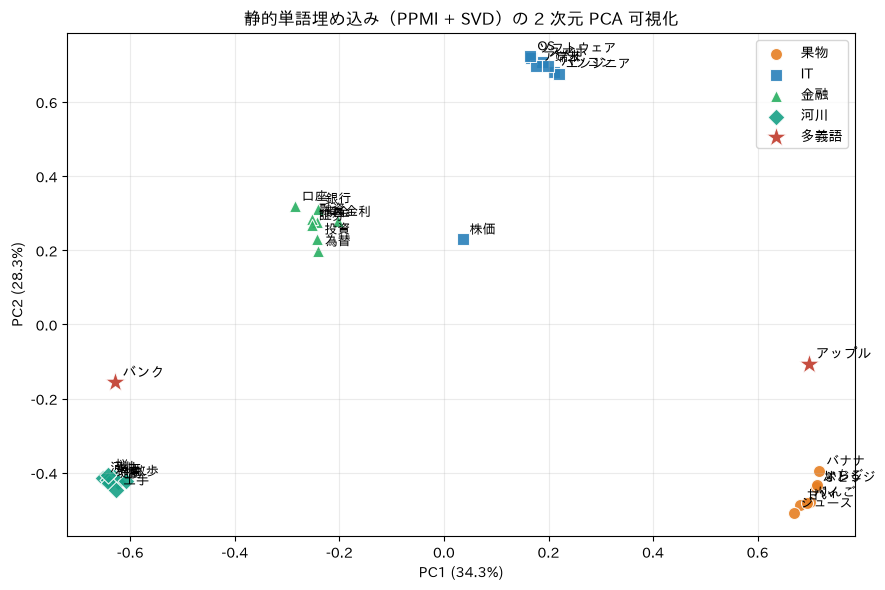

In [5]:
# 代表語をピックアップして 2 次元 PCA で可視化
domain_words = {
    "果物": ["りんご", "バナナ", "オレンジ", "ぶどう", "いちご", "甘い", "ジュース", "パイ"],
    "IT": ["パソコン", "スマホ", "ソフトウェア", "アプリ", "エンジニア", "端末", "OS", "株価"],
    "金融": ["銀行", "口座", "預金", "融資", "金利", "証券", "投資", "為替"],
    "河川": ["川", "河川", "水面", "橋", "堤防", "土手", "桜", "散歩"],
    "多義語": ["アップル", "バンク"],
}

plot_words = [w for words in domain_words.values() for w in words if w in word2idx]
plot_vecs = np.array([static_embeddings[word2idx[w]] for w in plot_words])

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(plot_vecs)
word2coord = {w: coords[i] for i, w in enumerate(plot_words)}

colors = {
    "果物": "#e67e22",
    "IT": "#2980b9",
    "金融": "#27ae60",
    "河川": "#16a085",
    "多義語": "#c0392b",
}
markers = {"果物": "o", "IT": "s", "金融": "^", "河川": "D", "多義語": "*"}

fig, ax = plt.subplots(figsize=(9, 6))
for domain, words in domain_words.items():
    xs = [word2coord[w][0] for w in words if w in word2coord]
    ys = [word2coord[w][1] for w in words if w in word2coord]
    size = 240 if domain == "多義語" else 75
    ax.scatter(xs, ys, c=colors[domain], marker=markers[domain], s=size, label=domain, alpha=0.9, edgecolors="white", linewidth=0.8)
    for w in words:
        if w in word2coord:
            x, y = word2coord[w]
            ax.annotate(w, (x, y), xytext=(5, 4), textcoords="offset points", fontsize=10 if domain == "多義語" else 9)

ax.set_title("静的単語埋め込み（PPMI + SVD）の 2 次元 PCA 可視化")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(frameon=True)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

---

## 2. 静的埋め込みの限界：多義語が 1 ベクトルに潰れる問題

静的埋め込み（Word2Vec / GloVe / fastText / PPMI+SVD）では、**1 つの表層形（単語）に対して固定の 1 ベクトル**しか割り当てられません。
そのため、多義語は「それぞれの語義が出現する文脈の重み付き平均（中間地点）」に引っ張られます。

各ドメインの重心ベクトル（プロトタイプ）とのコサイン類似度を計算して、単義語と多義語の違いを定量的に確認しましょう。

In [6]:
def domain_centroid(words):
    vecs = np.array([static_embeddings[word2idx[w]] for w in words if w in word2idx])
    c = vecs.mean(axis=0)
    return c / np.linalg.norm(c)

centroids = {
    "果物ドメイン": domain_centroid(["りんご", "バナナ", "オレンジ", "ぶどう", "いちご", "甘い", "ジュース", "パイ"]),
    "ITドメイン": domain_centroid(["パソコン", "スマホ", "ソフトウェア", "アプリ", "エンジニア", "端末", "OS", "株価"]),
    "金融ドメイン": domain_centroid(["銀行", "口座", "預金", "融資", "金利", "証券", "投資", "為替"]),
    "河川ドメイン": domain_centroid(["川", "河川", "水面", "橋", "堤防", "土手", "桜", "散歩"]),
}

target_words = ["りんご", "スマホ", "アップル", "銀行", "川", "バンク"]
rows = []
for w in target_words:
    vec = static_embeddings[word2idx[w]]
    row = {"単語": w}
    for dname, cvec in centroids.items():
        row[dname] = round(float(vec @ cvec), 3)
    rows.append(row)

df_poly = pd.DataFrame(rows).set_index("単語")
display(df_poly)

,果物ドメイン,ITドメイン,金融ドメイン,河川ドメイン
単語,,,,
りんご,0.999,-0.001,-0.001,0.001
スマホ,0.033,0.999,0.037,0.001
アップル,0.886,0.469,0.025,-0.001
銀行,-0.001,0.035,0.971,0.003
川,0.001,0.006,0.036,0.975
バンク,0.016,0.070,0.571,0.800


表を見ると、以下のように**単義語**と**多義語**の振る舞いが明確に異なります。
- **単義語**（「りんご」「スマホ」「銀行」「川」）は所属ドメインに対して高い類似度（約 0.97〜1.00）を持ち、他ドメインとはほぼ無相関または負の類似度です。
- **多義語**（「アップル」「バンク」）は **2 つの異なるドメインの両方に対して中〜高程度の類似度** を同時に持ってしまいます。

つまり静的埋め込みのままでは、「甘いアップルパイを食べた」の「アップル」と「アップルが新型スマホを発表した」の「アップル」を**まったく同じベクトル**として扱ってしまい、コサイン類似度は常に `1.000` になってしまいます。

---

## 3. 文脈付き埋め込み（Contextual Embeddings）による多義語の分離

Transformer（BERT など）の中核である **Self-Attention** では、文中の各トークンが**周囲のトークンとの関連度（注意重み）に応じて情報を集約**し、文脈に依存した表現ベクトルを動的に生成します。

まず CPU のみで原理を直感的に理解するため、先ほどの静的埋め込み $e_i$ を使って**簡易 Self-Attention 型文脈ベクトル**を実装してみましょう。
文中の対象語 $t$ の位置に対して、周囲の語 $j \neq t$ との類似度から注意重み $a_{tj}$ を計算し、自己表現と文脈表現を合成します。

$$a_{tj} = \frac{\exp\left(\tau \cdot e_t^\top e_j\right)}{\sum_{k \neq t} \exp\left(\tau \cdot e_t^\top e_k\right)}, \qquad h_t = \mathrm{normalize}\left((1 - \lambda) e_t + \lambda \sum_{j \neq t} a_{tj} e_j\right)$$

ここでは「アップル」を含む果物文脈 5 文と IT 企業文脈 5 文（計 10 文）を用意し、**静的ベクトル**と**文脈付きベクトル**で文間の類似度行列がどう変わるか比較します。

In [7]:
test_sentences = [
    # 果物文脈 (F1 - F5)
    ("F1: 果物", "新鮮 な アップル を 絞っ た 甘い ジュース を 食べる"),
    ("F2: 果物", "農家 が 収穫 し た アップル と りんご で パイ を 焼く"),
    ("F3: 果物", "甘い アップル と バナナ と いちご の デザート"),
    ("F4: 果物", "果物 売り場 で 甘い オレンジ と アップル を 買う"),
    ("F5: 果物", "温かい アップル パイ に ぶどう の 果実 を 添える"),
    # IT 企業文脈 (T1 - T5)
    ("T1: IT", "アップル が 新しい スマホ 端末 と OS を 発表 する"),
    ("T2: IT", "アップル の エンジニア が パソコン 向け ソフトウェア を 開発 する"),
    ("T3: IT", "アップル 製品 の 売上 が 伸び て 企業 の 株価 が 上がる"),
    ("T4: IT", "IT 企業 の アップル が 最新 アプリ と OS を 発表 する"),
    ("T5: IT", "アップル の 新しい パソコン と スマホ 端末 が 人気 だ"),
]

def contextual_embedding(sentence_str, target_word="アップル", lam=0.75, temp=3.0):
    tokens = [w for w in sentence_str.split() if w in word2idx]
    t_idx = tokens.index(target_word)
    e_t = static_embeddings[word2idx[target_word]]
    context_words = [w for i, w in enumerate(tokens) if i != t_idx]
    ctx_vecs = np.array([static_embeddings[word2idx[w]] for w in context_words])

    # Scaled dot-product 風の注意重み
    scores = (ctx_vecs @ e_t) * temp
    scores = scores - scores.max()
    weights = np.exp(scores)
    weights = weights / weights.sum()

    ctx_agg = weights @ ctx_vecs
    h_t = (1.0 - lam) * e_t + lam * ctx_agg
    h_t = h_t / np.linalg.norm(h_t)
    return h_t, [(w, round(float(wt), 3)) for w, wt in zip(context_words, weights)]

labels = [lbl for lbl, _ in test_sentences]
static_vecs = np.array([static_embeddings[word2idx["アップル"]] for _ in test_sentences])
ctx_vecs = []
for lbl, sent in test_sentences:
    h, w_info = contextual_embedding(sent, target_word="アップル")
    ctx_vecs.append(h)
    if lbl in ("F1: 果物", "T1: IT"):
        print(f"[{lbl}] 注意重み上位: {sorted(w_info, key=lambda x: -x[1])[:4]}")

ctx_vecs = np.array(ctx_vecs)
sim_static = cosine_similarity(static_vecs)
sim_ctx = cosine_similarity(ctx_vecs)

# 同一語義ペア（果物-果物, IT-IT）vs 異語義ペア（果物-IT）の平均類似度
def summarize_pair_sims(sim_mat):
    intra, inter = [], []
    for i in range(len(labels)):
        for j in range(i + 1, len(labels)):
            same_sense = (i < 5 and j < 5) or (i >= 5 and j >= 5)
            (intra if same_sense else inter).append(sim_mat[i, j])
    return float(np.mean(intra)), float(np.mean(inter))

intra_st, inter_st = summarize_pair_sims(sim_static)
intra_ct, inter_ct = summarize_pair_sims(sim_ctx)

summary_df = pd.DataFrame([
    {"表現手法": "静的埋め込み (PPMI+SVD)", "同一語義ペア平均類似度": round(intra_st, 3), "異語義ペア平均類似度": round(inter_st, 3), "分離マージン (差)": round(intra_st - inter_st, 3)},
    {"表現手法": "文脈付き埋め込み (簡易Attention)", "同一語義ペア平均類似度": round(intra_ct, 3), "異語義ペア平均類似度": round(inter_ct, 3), "分離マージン (差)": round(intra_ct - inter_ct, 3)},
])
display(summary_df)

[F1: 果物] 注意重み上位: [('絞っ', 0.207), ('新鮮', 0.206), ('食べる', 0.205), ('甘い', 0.196)]
[T1: IT] 注意重み上位: [('新しい', 0.215), ('スマホ', 0.205), ('発表', 0.204), ('端末', 0.191)]


,表現手法,同一語義ペア平均類似度,異語義ペア平均類似度,分離マージン (差)
0,静的埋め込み (PPMI+SVD),1.000,1.000,-0.000
1,文脈付き埋め込み (簡易Attention),0.931,0.437,0.495


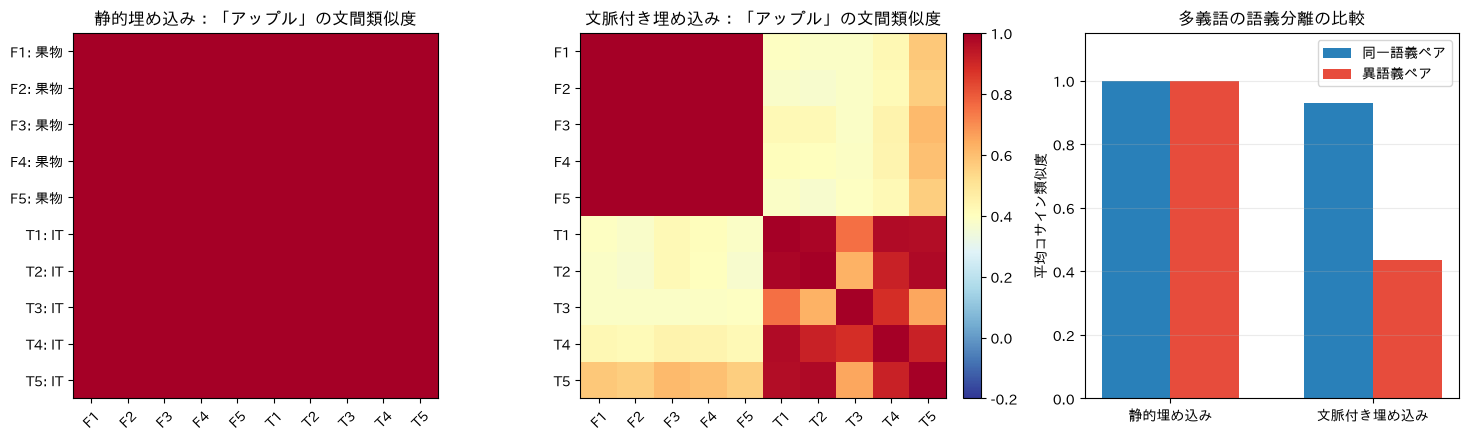

In [8]:
# ヒートマップ（静的 vs 文脈付き）と分離マージンの棒グラフで可視化
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1, 0.9]})

im0 = axes[0].imshow(sim_static, vmin=-0.2, vmax=1.0, cmap="RdYlBu_r")
axes[0].set_title("静的埋め込み：「アップル」の文間類似度")
axes[0].set_xticks(range(len(labels)))
axes[0].set_yticks(range(len(labels)))
axes[0].set_xticklabels([l.split(":")[0] for l in labels], rotation=45)
axes[0].set_yticklabels(labels)

im1 = axes[1].imshow(sim_ctx, vmin=-0.2, vmax=1.0, cmap="RdYlBu_r")
axes[1].set_title("文脈付き埋め込み：「アップル」の文間類似度")
axes[1].set_xticks(range(len(labels)))
axes[1].set_yticks(range(len(labels)))
axes[1].set_xticklabels([l.split(":")[0] for l in labels], rotation=45)
axes[1].set_yticklabels([l.split(":")[0] for l in labels])
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

x = np.arange(2)
width = 0.34
axes[2].bar(x - width/2, [intra_st, intra_ct], width, label="同一語義ペア", color="#2980b9")
axes[2].bar(x + width/2, [inter_st, inter_ct], width, label="異語義ペア", color="#e74c3c")
axes[2].set_xticks(x)
axes[2].set_xticklabels(["静的埋め込み", "文脈付き埋め込み"])
axes[2].set_ylim(0, 1.15)
axes[2].set_ylabel("平均コサイン類似度")
axes[2].set_title("多義語の語義分離の比較")
axes[2].legend()
axes[2].grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

ヒートマップを見ると、静的埋め込みでは全ペアが真っ赤（`1.000`）で区別できていないのに対し、文脈付き埋め込みでは **果物クラスタ（F1〜F5）** と **IT クラスタ（T1〜T5）** が明確なブロック対角構造に分かれていることが分かります。

同様に、「バンク（金融 vs 河川）」でもドメイン重心との類似度が文脈によって正しく切り替わることを確認しておきましょう。

In [9]:
bank_cases = [
    ("金融文脈", "バンク の 支店 で 口座 の 預金 と 融資 の 金利 を 確認 する"),
    ("河川文脈", "川 の バンク 沿い の 堤防 と 土手 で 桜 と 水面 を 眺める"),
]

rows = []
for ctx_name, sent in bank_cases:
    h_vec, _ = contextual_embedding(sent, target_word="バンク")
    rows.append({
        "文脈": ctx_name,
        "金融ドメイン類似度": round(float(h_vec @ centroids["金融ドメイン"]), 3),
        "河川ドメイン類似度": round(float(h_vec @ centroids["河川ドメイン"]), 3),
    })

display(pd.DataFrame(rows).set_index("文脈"))

,金融ドメイン類似度,河川ドメイン類似度
文脈,,
金融文脈,0.905,0.240
河川文脈,0.180,0.982


---

## 4. 【発展】日本語 BERT による実際の文脈付き埋め込みの抽出（Colab 向け）

実際の自然言語処理では、大規模コーパスで事前学習された **日本語 BERT（`tohoku-nlp/bert-base-japanese-v3`）** などの Transformer モデルから文脈付き埋め込みを抽出します。

以下のセルは `transformers` と `torch` がインストールされた環境（Google Colab 等）でそのまま実行できます。
未導入環境やオフライン環境でもエラーで止まらないよう例外処理を入れています。Colab で試す場合は、必要に応じて先頭で `!pip install -q "transformers[ja]" torch` を実行してください。

In [10]:
def demo_bert_contextual_embeddings():
    import torch
    warnings.filterwarnings("ignore", message="IProgress not found")
    from transformers import AutoModel, AutoTokenizer
    from transformers.utils import logging as hf_logging

    hf_logging.set_verbosity_error()
    hf_logging.disable_progress_bar()

    model_name = "tohoku-nlp/bert-base-japanese-v3"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()

    bert_sentences = [
        ("果物1", "甘いアップルパイを焼いてデザートに食べた。"),
        ("果物2", "新鮮なアップルを絞ったジュースがとても美味しい。"),
        ("IT1", "アップルが新しいスマートフォンとパソコンを発表した。"),
        ("IT2", "アップルの最新OSアップデートがエンジニアから注目されている。"),
    ]

    vecs = []
    for tag, text in bert_sentences:
        inputs = tokenizer(text, return_tensors="pt")
        tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
        with torch.no_grad():
            hidden = model(**inputs).last_hidden_state[0]  # (seq_len, 768)

        # 「アップル」に対応するトークン（サブワード分割時は平均）を抽出
        target_indices = [i for i, tok in enumerate(tokens) if "アップル" in tok]
        if not target_indices:
            raise ValueError(f"対象語がトークン列に見つかりません: {tokens}")
        vec = hidden[target_indices].mean(dim=0).numpy()
        vec = vec / np.linalg.norm(vec)
        vecs.append(vec)
        print(f"[{tag}] tokens={tokens[:10]}... -> 抽出位置={target_indices}")

    sim = cosine_similarity(np.array(vecs))
    tags = [t for t, _ in bert_sentences]
    display(pd.DataFrame(np.round(sim, 3), index=tags, columns=tags))

try:
    demo_bert_contextual_embeddings()
except Exception as e:
    print("※ 日本語 BERT デモをスキップしました（Colab 等のオンライン＋transformers 環境で実行できます）。")
    print(f"詳細: {type(e).__name__}: {e}")

[果物1] tokens=['[CLS]', '甘い', 'アップル', 'パイ', 'を', '焼い', 'て', 'デザート', 'に', '食べ']... -> 抽出位置=[2]
[果物2] tokens=['[CLS]', '新鮮', 'な', 'アップル', 'を', '絞', '##っ', 'た', 'ジュース', 'が']... -> 抽出位置=[3]
[IT1] tokens=['[CLS]', 'アップル', 'が', '新しい', 'スマート', 'フォン', 'と', 'パソコン', 'を', '発表']... -> 抽出位置=[1]
[IT2] tokens=['[CLS]', 'アップル', 'の', '最新', 'OS', 'アップデート', 'が', 'エンジニア', 'から', '注目']... -> 抽出位置=[1]


,果物1,果物2,IT1,IT2
果物1,1.000,0.904,0.684,0.727
果物2,0.904,1.000,0.704,0.763
IT1,0.684,0.704,1.000,0.907
IT2,0.727,0.763,0.907,1.000


---

## 5. まとめ

- **静的単語埋め込み（PPMI + SVD, Word2Vec 等）** は計算コストが小さく、単義語の意味的類似性をうまく捉えられる一方で、**多義語が 1 つのベクトルに統合されてしまう**限界があります。
- **文脈付き埋め込み（Self-Attention / BERT）** は、文中の周囲トークンに応じて表現ベクトルを動的に生成するため、同じ「アップル」でも果物文脈と IT 企業文脈を明確に分離できます。
- この「文脈に応じた表現生成」こそが、第2章・第3章で扱う **BERT による文書分類・固有表現認識（NER）** や **大規模言語モデル（LLM）** の高い精度を支える基盤になっています。